# EDA (Exploratory Data Analysis) of the Abalone dataset

The goal of the project is to predict the age of an abalone from physical measurements.
The age is given by the number of shell rings: **age (years) = Rings + 1.5**.
This notebook explores the dataset to understand the target, the features and the data quality issues
before building a first model in `modelling.ipynb`.

# Imports

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 500)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 72

# Data

The dataset is downloaded from [Kaggle](https://www.kaggle.com/datasets/rodolfomendes/abalone-dataset)
and stored locally in the `data/` folder (not versioned).

In [2]:
DATA_PATH = "../data/abalone.csv"
TARGET = "Rings"

df = pd.read_csv(DATA_PATH)
df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [3]:
print(f"Shape: {df.shape}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicated rows: {df.duplicated().sum()}")
df.dtypes

Shape: (4177, 9)
Missing values: 0
Duplicated rows: 0


Sex                   str
Length            float64
Diameter          float64
Height            float64
Whole weight      float64
Shucked weight    float64
Viscera weight    float64
Shell weight      float64
Rings               int64
dtype: object

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Length,4177.0,0.523992,0.120093,0.0750,0.4500,0.5450,0.615,0.8150
Diameter,4177.0,0.407881,0.099240,0.0550,0.3500,0.4250,0.480,0.6500
Height,4177.0,0.139516,0.041827,0.0000,0.1150,0.1400,0.165,1.1300
Whole weight,4177.0,0.828742,0.490389,0.0020,0.4415,0.7995,1.153,2.8255
Shucked weight,4177.0,0.359367,0.221963,0.0010,0.1860,0.3360,0.502,1.4880
Viscera weight,4177.0,0.180594,0.109614,0.0005,0.0935,0.1710,0.253,0.7600
Shell weight,4177.0,0.238831,0.139203,0.0015,0.1300,0.2340,0.329,1.0050
Rings,4177.0,9.933684,3.224169,1.0000,8.0000,9.0000,11.000,29.0000


# EDA

## Target: number of rings

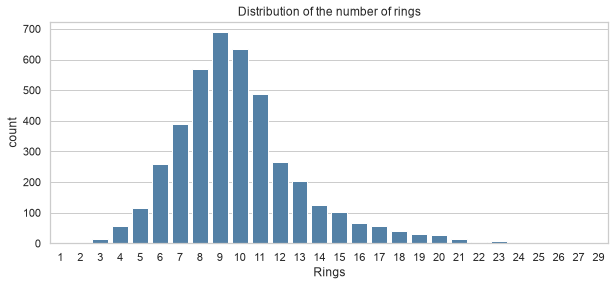

count    4177.000000
mean        9.933684
std         3.224169
min         1.000000
25%         8.000000
50%         9.000000
75%        11.000000
max        29.000000
Name: Rings, dtype: float64


In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.countplot(data=df, x=TARGET, color="steelblue", ax=ax)
ax.set_title("Distribution of the number of rings")
plt.show()

print(df[TARGET].describe())

The target ranges from 1 to 29 rings, with most abalones between 7 and 11 rings.
The distribution is right-skewed: old abalones (> 20 rings) are rare, so the model will have
few examples to learn from in that range.

## Categorical feature: Sex (M = male, F = female, I = infant)

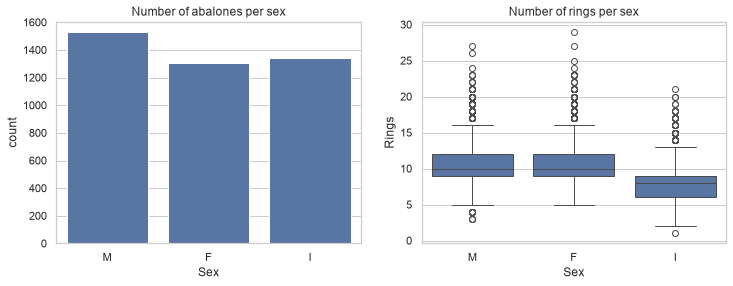

,count,mean,median
Sex,,,
F,1307,11.129304,10.0
I,1342,7.890462,8.0
M,1528,10.705497,10.0


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Sex", order=["M", "F", "I"], ax=axes[0])
axes[0].set_title("Number of abalones per sex")
sns.boxplot(data=df, x="Sex", y=TARGET, order=["M", "F", "I"], ax=axes[1])
axes[1].set_title("Number of rings per sex")
plt.show()

df.groupby("Sex")[TARGET].agg(["count", "mean", "median"])

The three classes are balanced. Infants have clearly fewer rings (median 8) than adults
(median 10 for both males and females), while males and females are very similar.
`Sex` is therefore informative, mainly to separate infants from adults, and must be encoded
(e.g. one-hot encoding) before modelling.

## Numerical features vs target

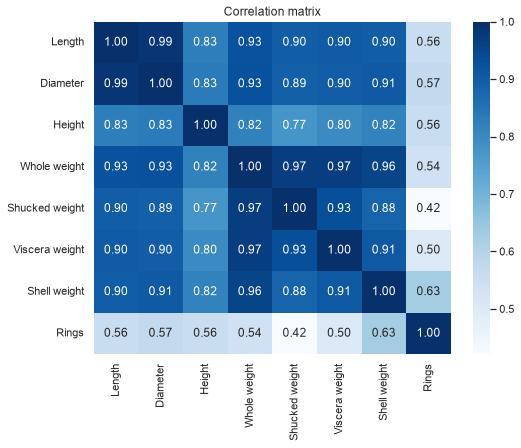

In [7]:
numerical_features = df.select_dtypes("number").columns.drop(TARGET).tolist()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    df[numerical_features + [TARGET]].corr(), annot=True, fmt=".2f", cmap="Blues", ax=ax
)
ax.set_title("Correlation matrix")
plt.show()

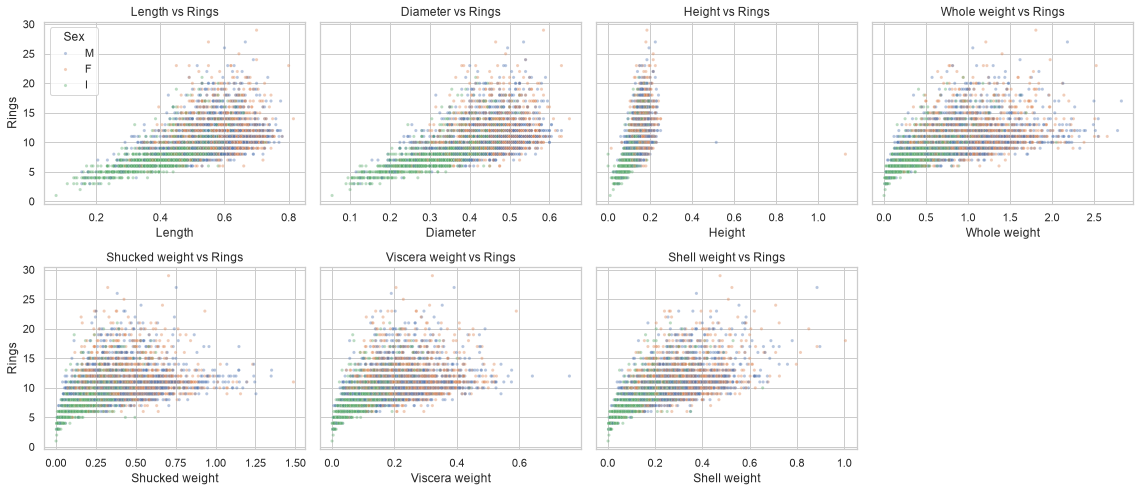

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
for ax, feature in zip(axes.flat, numerical_features):
    sns.scatterplot(
        data=df,
        x=feature,
        y=TARGET,
        hue="Sex",
        alpha=0.4,
        s=10,
        ax=ax,
        legend=ax is axes.flat[0],
    )
    ax.set_title(f"{feature} vs {TARGET}")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

- All measurements are positively correlated with the number of rings; `Shell weight` is the most
  correlated feature (0.63), `Shucked weight` the least (0.42).
- The features are highly correlated with each other (around 0.9 or more between lengths and between weights, ~0.8 for height):
  they all measure the size of the abalone. This multicollinearity matters for the interpretation of
  a linear model's coefficients, less for its predictive performance.
- The relationship with the target is not linear: the number of rings grows quickly for small
  abalones then flattens, and the variance increases with size (large abalones can be of very different ages).

## Data quality: outliers and inconsistent values

In [9]:
inconsistencies = {
    "Height == 0": df["Height"] == 0,
    "Height > 0.4": df["Height"] > 0.4,
    "Shucked weight > Whole weight": df["Shucked weight"] > df["Whole weight"],
}
for name, mask in inconsistencies.items():
    print(f"{name}: {mask.sum()} rows")

df[pd.concat(inconsistencies, axis=1).any(axis=1)]

Height == 0: 2 rows
Height > 0.4: 2 rows
Shucked weight > Whole weight: 4 rows


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
1216,I,0.310,0.225,0.070,0.1055,0.4350,0.0150,0.0400,5
1257,I,0.430,0.340,0.000,0.4280,0.2065,0.0860,0.1150,8
1417,M,0.705,0.565,0.515,2.2100,1.1075,0.4865,0.5120,10
2051,F,0.455,0.355,1.130,0.5940,0.3320,0.1160,0.1335,8
2627,I,0.275,0.205,0.070,0.1055,0.4950,0.0190,0.0315,5
2641,I,0.475,0.365,0.100,0.1315,0.2025,0.0875,0.1230,7
3086,I,0.355,0.270,0.075,0.2040,0.3045,0.0460,0.0595,7
3996,I,0.315,0.230,0.000,0.1340,0.0575,0.0285,0.3505,6


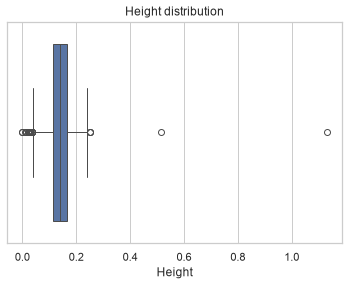

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="Height", ax=ax)
ax.set_title("Height distribution")
plt.show()

A few rows are physically impossible: 2 abalones with a height of 0, 2 with a height above 0.4
(far from the rest of the distribution, max ~0.25 otherwise), and 4 with a shucked weight greater
than the whole weight. They represent less than 0.3% of the dataset and can safely be removed.

# Conclusions

- **Clean dataset**: 4,177 rows, 8 features, no missing values and no duplicates.
- **Target**: `Rings` (1 to 29), right-skewed, centered around 9-10 rings. We treat it as a
  **regression** problem; errors on old abalones will be the hardest to reduce.
- **Features**: all physical measurements are positively correlated with the target (`Shell weight`
  being the best single predictor) and highly correlated with each other. `Sex` is useful mainly to
  distinguish infants from adults and needs to be one-hot encoded.
- **Data quality**: a handful of inconsistent rows (zero/extreme height, shucked weight > whole weight)
  should be removed during preprocessing.
- **Next step** (`modelling.ipynb`): start with a simple linear regression as a baseline, then try a
  non-linear model to capture the non-linear relationship observed above.